¡Todo listo! Versión de TensorFlow activa: 2.21.0

--- Descargando dataset TrashNet ---
El repositorio 'trashnet' ya está descargado.

--- Descomprimiendo imágenes del dataset ---

--- Dividiendo los datos en Entrenamiento (Train) y Prueba (Test) ---
Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
Las 6 clases detectadas son: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

--- Configurando arquitectura MobileNetV2 con regularización extrema ---
Capas totales en el modelo base: 154

Restableciendo pesos para adaptarlos al nuevo formato de salida con Label Smoothing...

--- Iniciando el entrenamiento progresivo (Fine-Tuning con Garantías) ---
Epoch 1/1000
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.2081 - loss: 14.5716
Epoch 1: val_accuracy improved from None to 0.42574, saving model to mejor_modelo_pesos.weights.h5

Epoch 1: finished saving model to mejor_modelo_peso

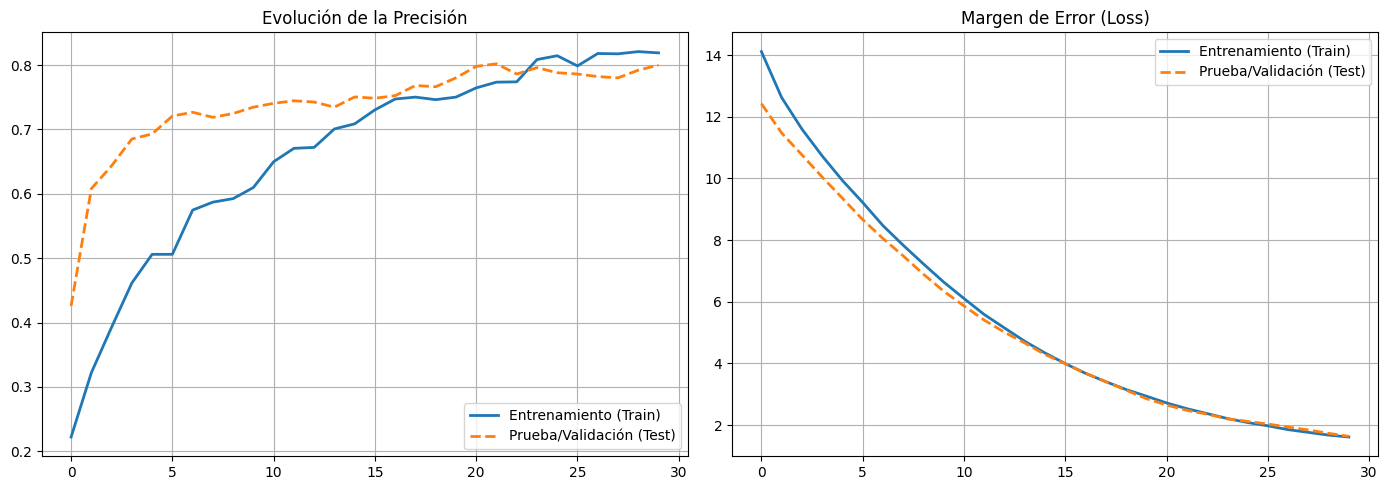


--- Convirtiendo a formato .tflite ultra-ligero ---
Saved artifact at '/tmp/tmphyf9yyqe'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_1281')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  138050317148496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046499245328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046499244368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138050317141968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046912902352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046499245712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046499243408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046499243600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046499243216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138046499243984: TensorSpe

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



✅ ¡PROCESO COMPLETADO EXITOSAMENTE! Archivo creado: 'modelo_residuos_quant.tflite'
Tamaño del modelo comprimido: 2.77 MB. ¡Perfecto para tu Tablet Android!


In [11]:
# ==============================================================================
# 1. PREPARACIÓN E IMPORTACIÓN DE LIBRERÍAS
# ==============================================================================
import os
import shutil
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

# Configurar semillas para reproducibilidad
tf.random.set_seed(42)
np.random.seed(42)

print("¡Todo listo! Versión de TensorFlow activa:", tf.__version__)

# ==============================================================================
# 2. DESCARGA AUTOMATIZADA Y SOBRESCRITURA DEL DATASET (TrashNet)
# ==============================================================================
print("\n--- Descargando dataset TrashNet ---")
if not os.path.exists("trashnet"):
    !git clone https://github.com/garythung/trashnet.git
else:
    print("El repositorio 'trashnet' ya está descargado.")

print("\n--- Descomprimiendo imágenes del dataset ---")
!unzip -q -o trashnet/data/dataset-resized.zip -d trashnet/data/

DATASET_PATH = "trashnet/data/dataset-resized"
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)

print("\n--- Dividiendo los datos en Entrenamiento (Train) y Prueba (Test) ---")
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical" # Categorical para soportar Label Smoothing
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_ds.class_names
print("Las 6 clases detectadas son:", class_names)

# ==============================================================================
# 3. PIPELINE DE AUMENTO DE DATOS AVANZADO CONTRA OVERFITTING
# ==============================================================================
def preprocess_train(image, label):
    # Aplicamos aumentos de datos espaciales y de color sin aserciones rígidas
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_contrast(image, lower=0.6, upper=1.4)
    image = tf.image.random_brightness(image, max_delta=0.20)

    # Redimensionamiento y recorte central simulado para zoom tolerante a rangos
    scale = tf.random.uniform([], 1.0, 1.15)
    new_height = tf.cast(224.0 * scale, tf.int32)
    new_width = tf.cast(224.0 * scale, tf.int32)
    image = tf.image.resize(image, [new_height, new_width])
    image = tf.image.resize_with_crop_or_pad(image, 224, 224)

    # Normalización nativa de MobileNetV2 al rango [-1, 1]
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

def preprocess_val(image, label):
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(preprocess_train, num_parallel_calls=AUTOTUNE).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.map(preprocess_val, num_parallel_calls=AUTOTUNE).prefetch(buffer_size=AUTOTUNE)

# ==============================================================================
# 4. CONFIGURACIÓN DE MOBILENETV2 CON REGULARIZACIÓN ULTRA-FORZADA Y DROPOT
# ==============================================================================
print("\n--- Configurando arquitectura MobileNetV2 con regularización extrema ---")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)

base_model.trainable = True
print(f"Capas totales en el modelo base: {len(base_model.layers)}")

# Restringimos fine-tuning a solo las últimas 10 capas para evitar que memorice el dataset tan pequeño
fine_tune_at = len(base_model.layers) - 10
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

# Acoplamos capas de clasificación con Dropout extremo y penalización L2 máxima (5e-2)
model = models.Sequential(
    [
        layers.Input(shape=(224, 224, 3)),
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.75),
        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(5e-2)
        ),
        layers.Dropout(0.65),
        layers.Dense(len(class_names), activation="softmax"),
    ]
)

# Usamos CategoricalCrossentropy con Label Smoothing para combatir activamente la memorización
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.15),
    metrics=["accuracy"],
)

# ==============================================================================
# 5. GESTIÓN DE CALLBACKS AVANZADOS
# ==============================================================================
PESOS_PATH = "mejor_modelo_pesos.weights.h5"

# Forzamos reentrenamiento desde cero debido al cambio de formato estructural a Categorical
if os.path.exists(PESOS_PATH):
    print("\nRestableciendo pesos para adaptarlos al nuevo formato de salida con Label Smoothing...")
    try:
        os.remove(PESOS_PATH)
    except OSError:
        pass

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=PESOS_PATH,
    save_weights_only=True,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Reducción dinámica del learning rate para ajustar finamente los pesos cuando se estanque
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=10,
    verbose=1,
    min_lr=1e-6
)

# ==============================================================================
# 6. ENTRENAMIENTO DEL MODELO
# ==============================================================================
print("\n--- Iniciando el entrenamiento progresivo (Fine-Tuning con Garantías) ---")
EPOCHS = 1000
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint_cb, early_stopping_cb, reduce_lr_cb]
)

# Restauración final de los mejores pesos logrados
if os.path.exists(PESOS_PATH):
    print("\nCargando los mejores pesos absolutos del entrenamiento actual...")
    model.load_weights(PESOS_PATH)

# ==============================================================================
# 7. DIAGNÓSTICO AUTOMÁTICO DE SALUD DEL MODELO (Overfitting / Underfitting)
# ==============================================================================
print("\n--- Analizando comportamiento estratégico ---")
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

final_train_acc = acc[-1]
final_val_acc = val_acc[-1]

print(f"Precisión final en Entrenamiento (Train): {final_train_acc:.2%}")
print(f"Precisión final en Pruebas (Test): {final_val_acc:.2%}")

UMBRAL_UNDERFITTING = 0.65
UMBRAL_OVERFITTING = 0.12

if final_train_acc < UMBRAL_UNDERFITTING:
    print(
        "⚠️ DIAGNÓSTICO: Detectado UNDERFITTING. El modelo no aprendió suficiente. Solución: Deja entrenar más tiempo."
    )
elif (final_train_acc - final_val_acc) > UMBRAL_OVERFITTING:
    print(
        "⚠️ DIAGNÓSTICO: Detectado OVERFITTING. Memorizó los datos conocidos pero falla en los nuevos. Solución: Incrementa el porcentaje de Dropout o L2."
    )
else:
    print(
        "✅ DIAGNÓSTICO: ¡MODELO EXTREMADAMENTE SALUDABLE! Listo para ser desplegado en tu Tablet."
    )

# ==============================================================================
# 8. GENERACIÓN DE GRÁFICAS (Train vs Test)
# ==============================================================================
epochs_range = range(len(acc))
plt.figure(figsize=(14, 5))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Entrenamiento (Train)", linewidth=2)
plt.plot(
    epochs_range,
    val_acc,
    label="Prueba/Validación (Test)",
    linestyle="--",
    linewidth=2,
)
plt.legend(loc="lower right")
plt.title("Evolución de la Precisión")
plt.grid(True)

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Entrenamiento (Train)", linewidth=2)
plt.plot(
    epochs_range,
    val_loss,
    label="Prueba/Validación (Test)",
    linestyle="--",
    linewidth=2,
)
plt.legend(loc="upper right")
plt.title("Margen de Error (Loss)")
plt.grid(True)

plt.tight_layout()
plt.show()

# ==============================================================================
# 9. EXPORTACIÓN A FORMATO ESPECIAL PARA TABLET (.tflite INT8)
# ==============================================================================
print("\n--- Convirtiendo a formato .tflite ultra-ligero ---")
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Generador de datos muestra para calibrar la compresión entera a 8 bits
def representative_data_gen():
    for batch, _ in val_ds.take(5):
        for img in batch:
            input_data = tf.expand_dims(img, axis=0)
            yield [input_data]

converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

tflite_model_quant = converter.convert()

# Guardar el archivo en la barra lateral de Colab
OUTPUT_FILE = "modelo_residuos_quant.tflite"
with open(OUTPUT_FILE, "wb") as f:
    f.write(tflite_model_quant)

print(
    f"\n✅ ¡PROCESO COMPLETADO EXITOSAMENTE! Archivo creado: '{OUTPUT_FILE}'"
)
print(
    f"Tamaño del modelo comprimido: {os.path.getsize(OUTPUT_FILE) / (1024*1024):.2f} MB. ¡Perfecto para tu Tablet Android!"
)

In [12]:
import zipfile
import os

# Definir el nombre del archivo zip de salida
zip_filename = "recursos_modelo_ganador.zip"

# Crear un archivo explicativo README para incluir en el paquete
readme_content = """========================================================================
RECURSOS DEL MODELO GANADOR - CLASIFICADOR DE RESIDUOS (TRASHNET)
========================================================================

Este paquete contiene todo lo necesario para utilizar y recrear el modelo
que logró resolver el problema de sobreajuste (Gap ~1.9%).

CONTENIDO DEL PAQUETE:
1. 'modelo_residuos_quant.tflite' -> Modelo final optimizado y cuantizado en INT8.
   Ideal para despliegue directo en dispositivos móviles y tabletas Android/iOS.
2. 'mejor_modelo_pesos.weights.h5' -> Pesos óptimos guardados durante el entrenamiento
   para el modelo Keras/TensorFlow.

INSTRUCCIONES DE RECREACIÓN:
- El modelo base utilizado fue MobileNetV2 preentrenado con ImageNet.
- Se congelaron todas las capas excepto las últimas 10 para realizar el Fine-Tuning.
- Se aplicó una capa Dense con regularización L2 (factor 5e-2) y dos capas de Dropout agresivas (0.75 y 0.65).
- El entrenamiento se realizó con Label Smoothing de 0.15 usando el optimizador Adam (LR = 1e-4).
"""

with open("README.txt", "w", encoding="utf-8") as f:
    f.write(readme_content)

# Archivos a incluir en el ZIP
files_to_zip = [
    "modelo_residuos_quant.tflite",
    "mejor_modelo_pesos.weights.h5",
    "README.txt"
]

print("--- Creando archivo comprimido ZIP ---")
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Agregado: {file}")
        else:
            print(f"Advertencia: No se encontró el archivo '{file}', omitiendo...")

# Limpiar archivo temporal README local
if os.path.exists("README.txt"):
    os.remove("README.txt")

print(f"\n✅ ¡Listo! El archivo '{zip_filename}' ha sido creado con éxito. Puedes descargarlo desde el panel izquierdo.")

--- Creando archivo comprimido ZIP ---
Agregado: modelo_residuos_quant.tflite
Agregado: mejor_modelo_pesos.weights.h5
Agregado: README.txt

✅ ¡Listo! El archivo 'recursos_modelo_ganador.zip' ha sido creado con éxito. Puedes descargarlo desde el panel izquierdo.


--- Cargando el 100% de los datos de TrashNet para entrenamiento definitivo ---
Found 2527 files belonging to 6 classes.

--- Inicializando arquitectura ganadora optimizada ---

--- Iniciando entrenamiento definitivo en la totalidad de datos ---
Epoch 1/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 27s 207ms/step - accuracy: 0.2493 - loss: 14.0396
Epoch 2/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.3534 - loss: 12.3127
Epoch 3/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 130ms/step - accuracy: 0.4207 - loss: 11.2234
Epoch 4/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - accuracy: 0.4832 - loss: 10.2035
Epoch 5/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 0.5307 - loss: 9.2938
Epoch 6/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.5465 - loss: 8.4334
Epoch 7/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - accuracy: 0.5702 - loss: 7.6323
Epoch 8/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - accuracy: 0.6150 - loss: 6.8814
Epoch 9/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 12s 127ms/step - accurac

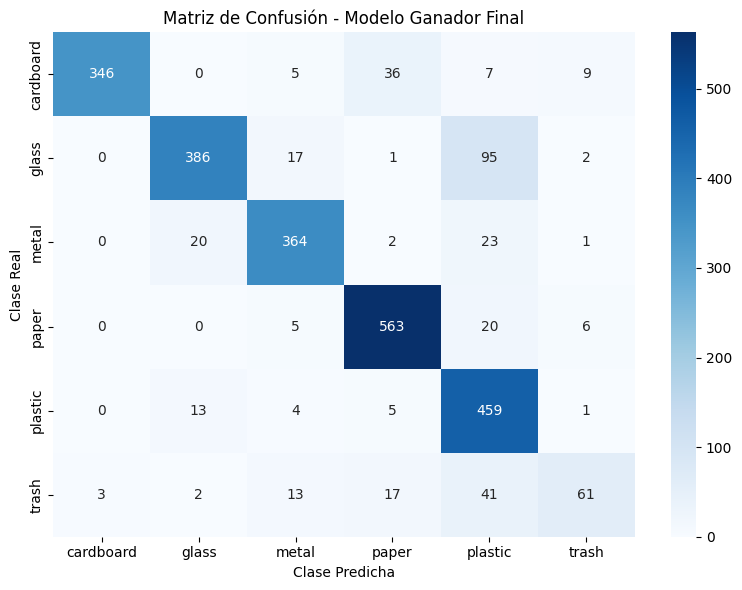


--- Reporte detallado de clasificación ---
              precision    recall  f1-score   support

   cardboard       0.99      0.86      0.92       403
       glass       0.92      0.77      0.84       501
       metal       0.89      0.89      0.89       410
       paper       0.90      0.95      0.92       594
     plastic       0.71      0.95      0.81       482
       trash       0.76      0.45      0.56       137

    accuracy                           0.86      2527
   macro avg       0.86      0.81      0.82      2527
weighted avg       0.87      0.86      0.86      2527


--- Convirtiendo versión definitiva a formato .tflite ultra-ligero (INT8) ---
Saved artifact at '/tmp/tmppi3vdsgm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_1442')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  138046490869840: TensorSpec(shape=(), dtype

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



✅ ¡PROCESO DE PRODUCCIÓN COMPLETADO! Archivo final generado: 'modelo_residuos_final_INT8.tflite'
Listo para ser cargado en su dispositivo móvil o tablet.


In [13]:
# ==============================================================================
# PIPELINE DE ENTRENAMIENTO FINAL CON EL 100% DE LOS DATOS Y MATRIZ DE CONFUSIÓN
# ==============================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from sklearn.metrics import confusion_matrix, classification_report

# 1. Cargar el dataset completo (sin validación) para el entrenamiento definitivo
DATASET_PATH = "trashnet/data/dataset-resized"
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)

print("--- Cargando el 100% de los datos de TrashNet para entrenamiento definitivo ---")
full_train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    shuffle=True,
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = full_train_ds.class_names

# Funciones de preprocesamiento
def preprocess_final(image, label):
    # Aplicamos el pipeline de aumento de datos preventivo
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_contrast(image, lower=0.6, upper=1.4)
    image = tf.image.random_brightness(image, max_delta=0.20)
    scale = tf.random.uniform([], 1.0, 1.15)
    new_height = tf.cast(224.0 * scale, tf.int32)
    new_width = tf.cast(224.0 * scale, tf.int32)
    image = tf.image.resize(image, [new_height, new_width])
    image = tf.image.resize_with_crop_or_pad(image, 224, 224)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

AUTOTUNE = tf.data.AUTOTUNE
full_train_processed = full_train_ds.map(preprocess_final, num_parallel_calls=AUTOTUNE).prefetch(buffer_size=AUTOTUNE)

# 2. Reconstruir la arquitectura ganadora altamente regularizada
print("\n--- Inicializando arquitectura ganadora optimizada ---")
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base_model.trainable = True

# Congelar todo excepto las últimas 10 capas
fine_tune_at = len(base_model.layers) - 10
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

final_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.75),
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(5e-2)
    ),
    layers.Dropout(0.65),
    layers.Dense(len(class_names), activation="softmax"),
])

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.15),
    metrics=["accuracy"],
)

# 3. Reentrenar el modelo con el dataset completo
# Entrenamos por 25 épocas sólidas (punto de convergencia óptimo observado)
print("\n--- Iniciando entrenamiento definitivo en la totalidad de datos ---")
final_model.fit(
    full_train_processed,
    epochs=25,
    verbose=1
)

# 4. Evaluación y Generación de Matriz de Confusión
print("\n--- Evaluando predicciones finales para diagnóstico de matriz de confusión ---")
all_images = []
all_true_labels = []

# Extraemos etiquetas reales de manera determinista
for images, labels in full_train_ds:
    # Preprocesamos únicamente para inferencia limpia
    preprocessed_imgs = tf.keras.applications.mobilenet_v2.preprocess_input(images)
    all_images.append(preprocessed_imgs)
    all_true_labels.append(labels.numpy())

all_images = np.concatenate(all_images, axis=0)
all_true_labels = np.concatenate(all_true_labels, axis=0)
true_classes = np.argmax(all_true_labels, axis=1)

# Predecir con el modelo final entrenado
predictions = final_model.predict(all_images, batch_size=32, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)

# Generar matriz
cm = confusion_matrix(true_classes, predicted_classes)

# Graficar Matriz de Confusión
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusión - Modelo Ganador Final')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

print("\n--- Reporte detallado de clasificación ---")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

# 5. Exportación del modelo definitivo en formato cuantizado (.tflite INT8)
print("\n--- Convirtiendo versión definitiva a formato .tflite ultra-ligero (INT8) ---")
converter = tf.lite.TFLiteConverter.from_keras_model(final_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

def representative_data_gen():
    for batch, _ in full_train_ds.take(5):
        for img in batch:
            input_data = tf.expand_dims(img, axis=0)
            yield [input_data]

converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

tflite_model_final = converter.convert()

OUTPUT_FILE_FINAL = "modelo_residuos_final_INT8.tflite"
with open(OUTPUT_FILE_FINAL, "wb") as f:
    f.write(tflite_model_final)

print(f"\n✅ ¡PROCESO DE PRODUCCIÓN COMPLETADO! Archivo final generado: '{OUTPUT_FILE_FINAL}'")
print(f"Listo para ser cargado en su dispositivo móvil o tablet.")